# Alzheimer MRI Dataset Audit


## 1. Setup
Import libraries and set the dataset path.


In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

# Setup dataset path
# Check both project root and notebooks/ directory so this notebook runs smoothly from either location
if Path('data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')
elif Path('../data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('../data/Alzheimer (Preprocessed Data)')
else:
    # Fallback to default expected path for clear error reporting
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')

print(f"Dataset path set to: {DATA_DIR.resolve()}")

Dataset path set to: C:\Users\usern\Desktop\Alzheimer-Detection\data\Alzheimer (Preprocessed Data)


## 2. Check Dataset
Verify that the dataset directory exists and list class folders.


In [2]:
# Verify dataset directory exists
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found at: {DATA_DIR.resolve()}\n"
        "Please make sure the dataset is placed inside 'data/Alzheimer (Preprocessed Data)'."
    )

# Discover class folders
class_folders = sorted([f for f in DATA_DIR.iterdir() if f.is_dir()])

print(f"Found {len(class_folders)} class folders:")
for folder in class_folders:
    print(f" - {folder.name}")

Found 4 class folders:
 - Mild_Demented
 - Moderate_Demented
 - Non_Demented
 - Very_Mild_Demented


## 3. Class Distribution
Count images in each class folder.


In [3]:
# Supported image extensions
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png'}

# Count images in each class folder
class_counts = []
total_images = 0

for folder in class_folders:
    # Find all supported image files
    image_files = [
        f for f in folder.iterdir() 
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]
    count = len(image_files)
    total_images += count
    
    class_counts.append({
        "Class": folder.name,
        "Image Count": count
    })

# Create a DataFrame for clear presentation
df_counts = pd.DataFrame(class_counts)
df_counts["Percentage (%)"] = (df_counts["Image Count"] / total_images) * 100
df_counts["Percentage (%)"] = df_counts["Percentage (%)"].round(2)

print(f"Total images found across all classes: {total_images}\n")
display(df_counts)

Total images found across all classes: 6400



,Class,Image Count,Percentage (%)
0,Mild_Demented,896,14.0
1,Moderate_Demented,64,1.0
2,Non_Demented,3200,50.0
3,Very_Mild_Demented,2240,35.0


## 4. Image Properties
Check image dimensions, color mode, and test for corrupt files.


In [4]:
# Track properties and corrupt files
dimensions_set = set()
modes_set = set()
formats_set = set()
corrupt_images = []
inspected_count = 0

for folder in class_folders:
    for img_path in folder.iterdir():
        if not (img_path.is_file() and img_path.suffix.lower() in IMAGE_EXTENSIONS):
            continue
            
        inspected_count += 1
        try:
            with Image.open(img_path) as img:
                dimensions_set.add(img.size)    # (width, height)
                modes_set.add(img.mode)         # 'L', 'RGB', etc.
                formats_set.add(img.format)     # 'JPEG', etc.
        except Exception as e:
            corrupt_images.append((str(img_path), str(e)))

print("--- Image Properties Summary ---")
print(f"Total images inspected: {inspected_count}")
print(f"Unique dimensions (width, height): {sorted(list(dimensions_set))}")
print(f"Unique color modes: {sorted(list(modes_set))}")
print(f"File formats: {sorted(list(formats_set))}")
print(f"Corrupt / unreadable images: {len(corrupt_images)}")

if corrupt_images:
    print("\nWarning: The following images failed to load:")
    for path, err in corrupt_images[:5]:
        print(f"  {path}: {err}")
else:
    print("\nSuccess: All images decoded cleanly with zero corrupt files!")

--- Image Properties Summary ---
Total images inspected: 6400
Unique dimensions (width, height): [(128, 128)]
Unique color modes: ['L']
File formats: ['JPEG']
Corrupt / unreadable images: 0

Success: All images decoded cleanly with zero corrupt files!


### Visualize Distribution
Plot the number of images per class.


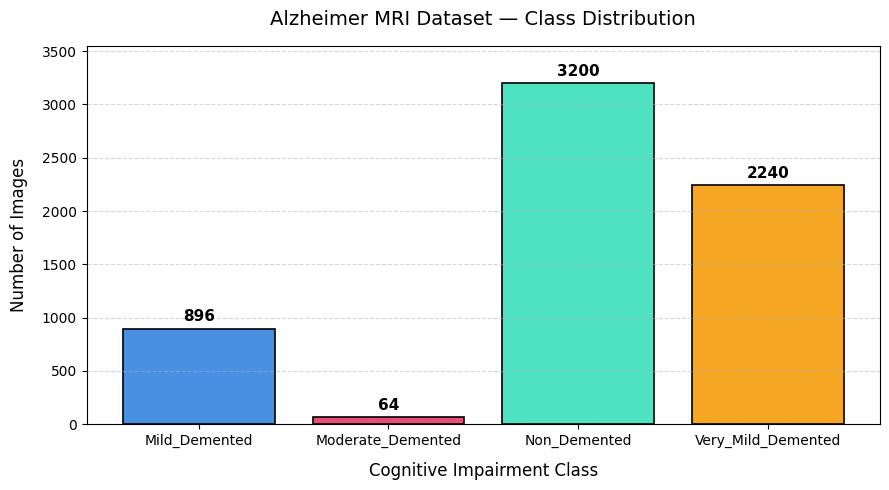

In [5]:
# Plot bar chart of class counts
plt.figure(figsize=(9, 5))
bars = plt.bar(
    df_counts["Class"],
    df_counts["Image Count"],
    color=["#4A90E2", "#E94E77", "#50E3C2", "#F5A623"],
    edgecolor="black",
    linewidth=1.2
)

plt.title("Alzheimer MRI Dataset — Class Distribution", fontsize=14, pad=15)
plt.xlabel("Cognitive Impairment Class", fontsize=12, labelpad=10)
plt.ylabel("Number of Images", fontsize=12, labelpad=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add exact count labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 40,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Add extra headroom on y-axis so labels fit comfortably
plt.ylim(0, max(df_counts["Image Count"]) + 350)
plt.tight_layout()
plt.show()

## 5. Sample Images
Display representative MRI scans from each class.


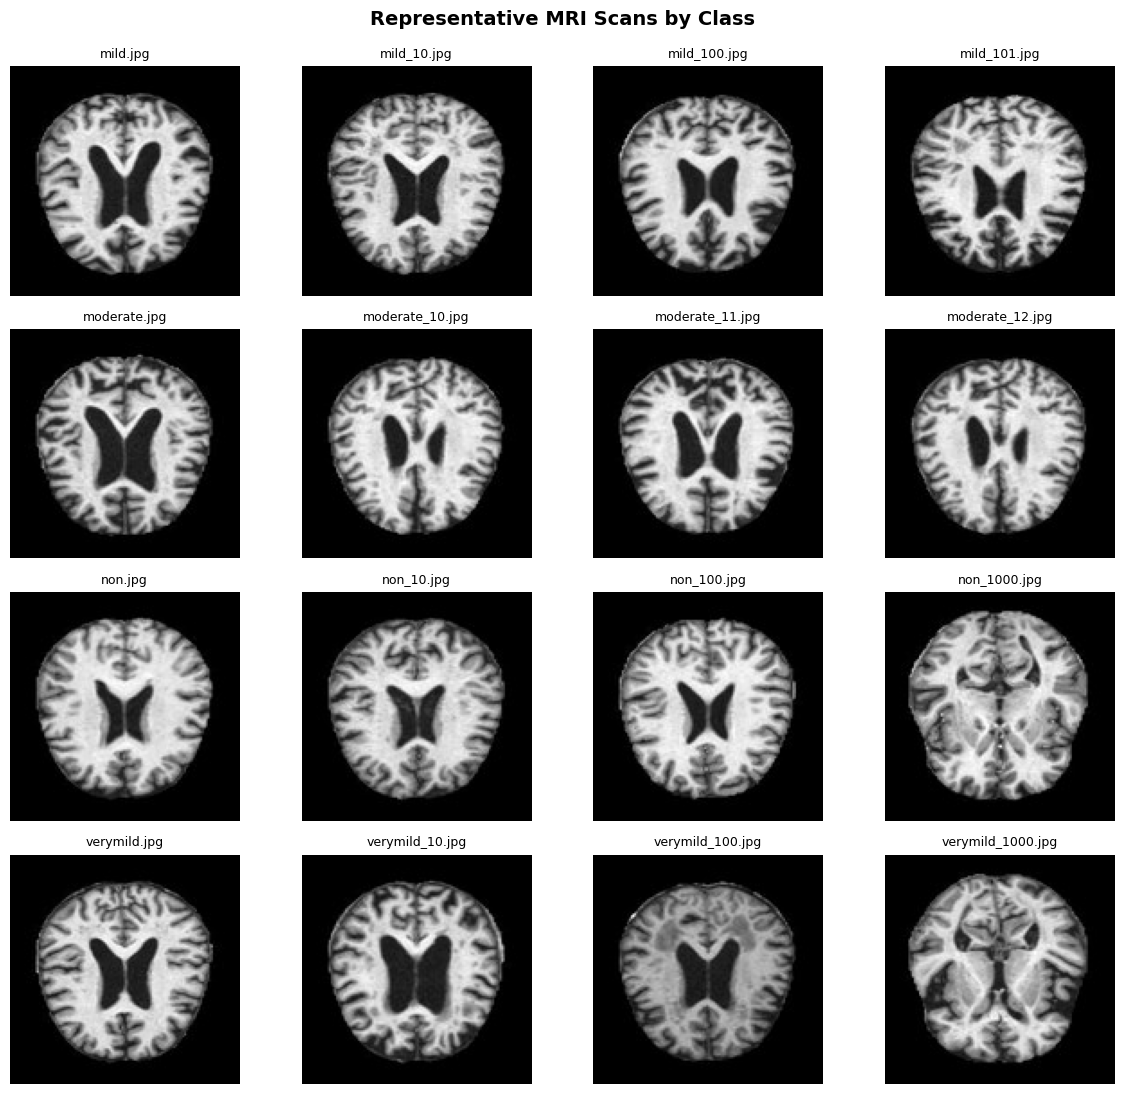

In [6]:
# Number of sample images to display per class
SAMPLES_PER_CLASS = 4

fig, axes = plt.subplots(len(class_folders), SAMPLES_PER_CLASS, figsize=(12, 11))

for row_idx, folder in enumerate(class_folders):
    # Get first few images from this class
    images_in_folder = sorted([
        f for f in folder.iterdir() 
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ])
    sample_files = images_in_folder[:SAMPLES_PER_CLASS]
    
    for col_idx, img_file in enumerate(sample_files):
        ax = axes[row_idx, col_idx]
        with Image.open(img_file) as img:
            # Display image in grayscale colormap
            ax.imshow(img, cmap="gray")
        
        # Title first image in row with class name; others with filename
        if col_idx == 0:
            ax.set_ylabel(folder.name.replace("_", " "), fontsize=10, fontweight="bold", labelpad=10)
        
        ax.set_title(img_file.name, fontsize=9)
        ax.axis("off")

plt.suptitle("Representative MRI Scans by Class", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

## 6. Check Duplicates
Check for exact duplicate files using MD5 hashes.


In [7]:
def calculate_file_hash(file_path):
    """Calculate the MD5 hash of a file."""
    hasher = hashlib.md5()
    with open(file_path, "rb") as f:
        # Read in chunks of 64KB
        for chunk in iter(lambda: f.read(65536), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

# Dictionary mapping MD5 hash to list of file paths
hash_to_paths = defaultdict(list)

for folder in class_folders:
    for img_path in folder.iterdir():
        if img_path.is_file() and img_path.suffix.lower() in IMAGE_EXTENSIONS:
            h = calculate_file_hash(img_path)
            hash_to_paths[h].append(img_path)

# Filter for hashes that appear more than once
duplicates = {h: paths for h, paths in hash_to_paths.items() if len(paths) > 1}

print("--- Duplicate Hash Check ---")
print(f"Total unique file hashes: {len(hash_to_paths)}")
print(f"Number of duplicate hash groups: {len(duplicates)}")

if duplicates:
    print(f"\nFound {len(duplicates)} duplicate sets:")
    for h, paths in list(duplicates.items())[:5]:
        print(f"\nHash: {h}")
        for p in paths:
            print(f"  - {p}")
else:
    print("\nResult: No exact duplicate files were found in the dataset.")
    print("Note: Having zero exact byte duplicates does NOT rule out visually identical")
    print("slices, near-duplicates, or multiple slices from the same subject/patient.")

--- Duplicate Hash Check ---
Total unique file hashes: 6400
Number of duplicate hash groups: 0

Result: No exact duplicate files were found in the dataset.
Note: Having zero exact byte duplicates does NOT rule out visually identical
slices, near-duplicates, or multiple slices from the same subject/patient.


## 7. Findings
- **Total images:** 6,400 across 4 classes
- **Image dimensions:** 128 × 128
- **Color mode:** Grayscale (mode `L`)
- **Corrupt images:** 0
- **Exact duplicates:** 0
- **Class imbalance:** `Moderate_Demented` has only 64 images (1%), while `Non_Demented` has 3,200 (50%)
- **Patient IDs:** Not available in filenames (slice-level data only)
- **Next steps:** Use stratified splits and convert images to 3-channel RGB for EfficientNet
